
## **NAMA  : AISYAH ASNI RAHMADANI**
## **NIM   : H061241079**
## **KELAS : B**

## <center>**KECEERDASAN ARTIFISIAL UNTUK GEOFISIKA**</center>
## <center>**R-CS-003 Synthetic Groundwater Transport Reference Implementation**</center>



### **Synthetic Groundwater Transport Reference Implementation**

Sumber Recipe: Buku *AI Cookbook untuk Earth Sciences: Prompt, Python, Scientific Modeling, dan Reproducible Workflows*  
Recipe ID: R-CS-003  
Chapter 25: Case Study: Groundwater Flow and Contaminant Transport  
Bidang: Hidrogeologi — Transpor Kontaminan Air Tanah  
Metode: Explicit Advection–Dispersion (Finite Volume) dengan Zero Boundary Flux  
Model: Transpor Konservatif Satu Dimensi (1D) pada Akuifer Homogen  
Jenis Data: Data Sintetis Hasil Simulasi Numerik

### **1. Tujuan**

Implementasi ini bertujuan menyimulasikan pergerakan pluma (*plume*) kontaminan konservatif di dalam akuifer jenuh satu dimensi menggunakan persamaan advection–dispersion yang diselesaikan dengan metode beda hingga eksplisit. Simulasi ini digunakan untuk memahami hubungan antara *hydraulic head*, Darcy flux, kecepatan pori, dispersi, kondisi batas, dan konsentrasi pada titik pemantauan sintetis.

Recipe R-CS-003 dalam buku menjadi dasar pemilihan alur pemodelan. Notebook ini merupakan implementasi yang disesuaikan dengan deskripsi recipe dalam buku, bukan salinan *source code* resmi.

### **2. Data dan Parameter yang Digunakan**

Simulasi tidak memakai data lapangan. Seluruh masukan dibangkitkan secara sintetis, yaitu domain homogen, konduktivitas hidraulik, porositas efektif, sumber berbentuk Gaussian, dan titik pemantauan dengan sumbu *x* positif ke arah *down-gradient*, sebagaimana dinyatakan dalam kontrak recipe.

Dua nilai yang disebutkan dalam buku dan dijadikan acuan adalah *Courant number* sebesar 0,015 dan *diffusion number* sebesar 0,045. Time step dihitung dari *Courant number* tersebut, sedangkan koefisien dispersi dipilih agar *diffusion number* yang dihasilkan sama dengan nilai di buku.

Nilai numerik lain, yaitu jumlah grid, jarak antargrid, konduktivitas hidraulik, gradien hidraulik, porositas efektif, dispersivitas, konsentrasi dan lebar sumber, serta posisi titik pemantau, **tidak tersedia pada teks buku yang dirujuk**. Parameter tersebut dinyatakan sebagai asumsi atau nilai contoh, bukan parameter resmi dari buku.

### **3. Metode**

Tahapan implementasi simulasi adalah sebagai berikut:

1. Menentukan grid ruang 1D dan parameter akuifer homogen.
2. Menghitung *hydraulic head*, Darcy flux, dan kecepatan pori dari gradien hidraulik.
3. Menghitung time step dari *Courant number* dan koefisien dispersi dari dispersivitas.
4. Membuat kondisi awal berupa sumber konsentrasi Gaussian.
5. Menghitung transpor advection–dispersion dengan skema eksplisit berbasis fluks antar sel (*finite volume*).
6. Menerapkan *zero boundary flux* pada kedua ujung domain.
7. Merekam *snapshot* konsentrasi dan deret waktu konsentrasi pada tiga titik pemantau.
8. Memeriksa stabilitas numerik, nilai hingga (*finite*), konsentrasi tidak negatif, dan kekekalan massa.
9. Membandingkan hasil numerik dengan solusi analitik pluma Gaussian sebagai pemeriksaan tambahan (bukan bagian dari recipe di buku).
10. Menampilkan serta menyimpan grafik, tabel, dan ringkasan parameter.

Hukum Darcy dan kecepatan pori yang digunakan adalah:

$$
q = -K \frac{dh}{dx}, \qquad v = \frac{q}{n_e}
$$

dengan keterangan:

- $K$ = konduktivitas hidraulik (m/s).
- $h$ = *hydraulic head* (m).
- $q$ = Darcy flux (m/s).
- $n_e$ = porositas efektif.
- $v$ = kecepatan pori atau kecepatan advektif (m/s).

Persamaan transpor advection–dispersion satu dimensi yang digunakan adalah:

$$
\frac{\partial C}{\partial t}
+
v \frac{\partial C}{\partial x}
=
D \frac{\partial^2 C}{\partial x^2},
\qquad
D = \alpha_L \, v
$$

dengan $C$ = konsentrasi (mg/L), $D$ = koefisien dispersi (m²/s), dan $\alpha_L$ = dispersivitas longitudinal (m). Untuk pemeriksaan stabilitas digunakan:

$$
Cr = \frac{v\,\Delta t}{\Delta x},
\qquad
Dn = \frac{D\,\Delta t}{\Delta x^2}
$$

### **4. Keluaran**

Notebook menghasilkan beberapa keluaran utama, yaitu:

- Profil *hydraulic head*: visualisasi gradien hidraulik yang menggerakkan aliran.
- Concentration snapshots: profil konsentrasi pada beberapa waktu, dibandingkan dengan solusi analitik.
- Monitoring time series: kurva konsentrasi terhadap waktu pada tiga titik pemantau.
- Ringkasan parameter dan pemeriksaan: *Courant number*, *diffusion number*, kekekalan massa, dan pemeriksaan numerik lainnya.
- File hasil: data numerik dan grafik yang disimpan dalam format CSV, JSON, dan PNG.


Jumlah titik grid     : 201
Jumlah langkah waktu  : 4800
DX                    : 1.0 m
Panjang domain        : 200 m
Darcy flux (q)        : 5.000e-07 m/s
Kecepatan pori (v)    : 1.667e-06 m/s (0.144 m/hari)
Dispersi (D)          : 5.000e-06 m2/s
DT                    : 9000.0 s (2.50 jam)
Durasi simulasi       : 500.0 hari
Courant number        : 0.015
Diffusion number      : 0.045
Peclet sel            : 0.333

Simulasi selesai.
Jumlah snapshot        : 6
Ukuran deret pantau    : (4801, 3)

Pemeriksaan numerik:
  Courant <= 1 dan Diffusion number <= 0.5 (stabil): LULUS
  Koefisien skema non-negatif (Peclet sel <= 2): LULUS
  Courant sesuai buku (0.015): LULUS
  Diffusion number sesuai buku (0.045): LULUS
  Konsentrasi finite: LULUS
  Konsentrasi tidak negatif: LULUS
  Massa terjaga (galat relatif < 1e-12): LULUS
  Sesuai solusi analitik (galat relatif < 1%): LULUS

Massa awal                 : 3.0080e+05 mg
Galat massa maksimum       : 1.746e-10 mg
Galat massa relatif        : 5.805e

,titik_pantau_x_m,konsentrasi_puncak_mg_per_L,waktu_puncak_hari,puncak_di_akhir_simulasi
0,50.0,35.465,119.8,False
1,80.0,22.844,327.4,False
2,110.0,17.598,500.0,True


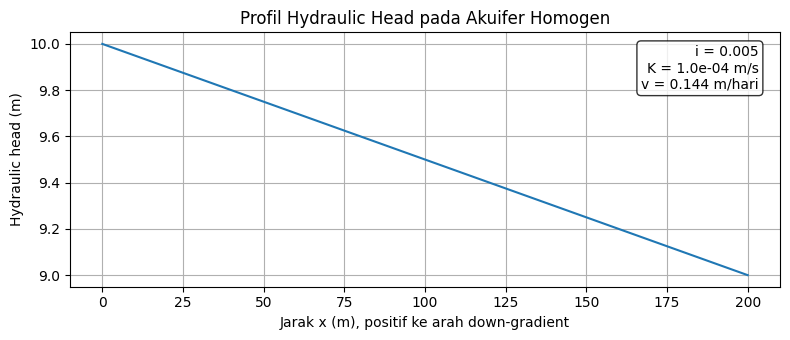

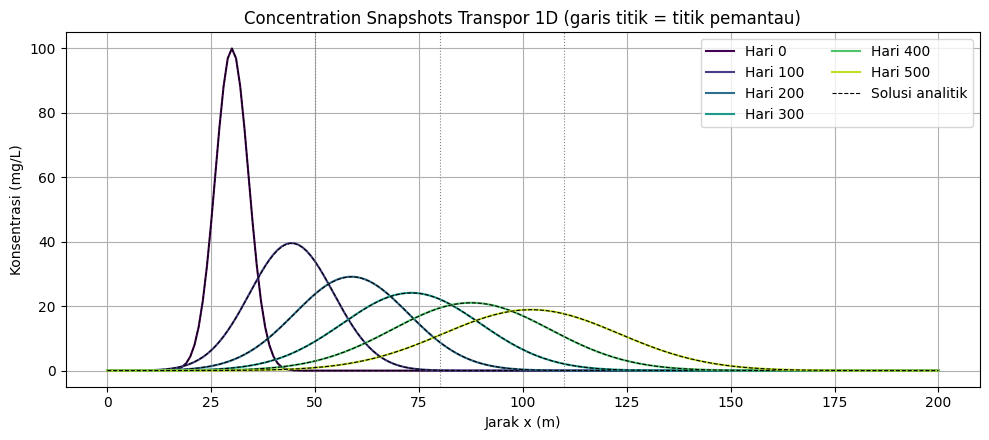

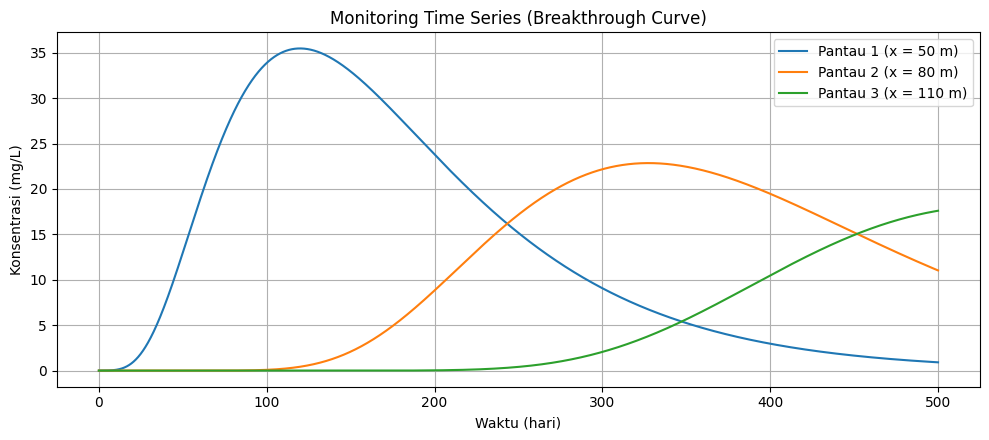

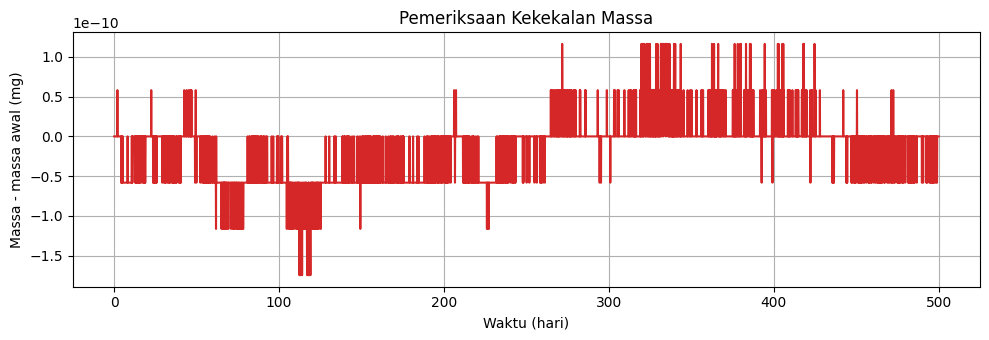


Hasil disimpan di folder: results_r_cs_003
Keluaran: 3 tabel CSV, 1 file JSON, dan 4 grafik PNG.


In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# 1. PARAMETER SIMULASI
# ============================================================

# Nilai yang disebutkan dalam buku (Chapter 25, kotak "Executed")
COURANT_BUKU = 0.015
DIFFUSION_BUKU = 0.045

# Parameter contoh untuk simulasi sintetis.
# Nilai ini bukan angka parameter asli yang dicantumkan dalam buku.
NX = 201                  # Jumlah sel/titik grid
DX = 1.0                  # Jarak antargrid (m)
NT = 4800                 # Jumlah langkah waktu

K = 1.0e-4                # Konduktivitas hidraulik (m/s), pasir bersih
NE = 0.30                 # Porositas efektif
H_HULU = 10.0             # Hydraulic head di x = 0 (m)
GRADIEN = 0.005           # Gradien hidraulik i = -dh/dx
ALPHA_L = 3.0             # Dispersivitas longitudinal (m)

C_MAKS = 100.0            # Konsentrasi puncak sumber Gaussian (mg/L)
X_SUMBER = 30.0           # Posisi pusat sumber (m)
SIGMA_SUMBER = 4.0        # Lebar sumber Gaussian (m)

POSISI_PANTAU_M = [50.0, 80.0, 110.0]   # Titik pemantau (m)
HARI_SNAPSHOT = [0, 100, 200, 300, 400, 500]

LUAS_PENAMPANG = 1.0      # Luas penampang akuifer (m2), untuk menghitung massa
DETIK_PER_HARI = 86400.0

# ============================================================
# 2. GRID, HYDRAULIC HEAD, DARCY FLUX, DAN KECEPATAN PORI
# ============================================================

x = np.arange(NX) * DX
panjang_domain = x[-1]

# Head linear pada akuifer homogen kondisi tunak
head = H_HULU - GRADIEN * x

# Darcy flux q = -K dh/dx dan kecepatan pori v = q / ne
darcy_flux = -K * np.gradient(head, DX)
kecepatan_pori = float(np.mean(darcy_flux / NE))

# Koefisien dispersi D = alpha_L * v
D = ALPHA_L * kecepatan_pori

# Time step dihitung dari Courant number acuan buku
DT = COURANT_BUKU * DX / kecepatan_pori

COURANT = kecepatan_pori * DT / DX
DIFFUSION_NUM = D * DT / DX**2
PECLET_SEL = kecepatan_pori * DX / D

time_s = np.arange(NT + 1) * DT
time_hari = time_s / DETIK_PER_HARI

indeks_pantau = [int(round(p / DX)) for p in POSISI_PANTAU_M]

print(f"Jumlah titik grid     : {NX}")
print(f"Jumlah langkah waktu  : {NT}")
print(f"DX                    : {DX} m")
print(f"Panjang domain        : {panjang_domain:.0f} m")
print(f"Darcy flux (q)        : {darcy_flux.mean():.3e} m/s")
print(f"Kecepatan pori (v)    : {kecepatan_pori:.3e} m/s "
      f"({kecepatan_pori * DETIK_PER_HARI:.3f} m/hari)")
print(f"Dispersi (D)          : {D:.3e} m2/s")
print(f"DT                    : {DT:.1f} s ({DT / 3600:.2f} jam)")
print(f"Durasi simulasi       : {time_hari[-1]:.1f} hari")
print(f"Courant number        : {COURANT:.3f}")
print(f"Diffusion number      : {DIFFUSION_NUM:.3f}")
print(f"Peclet sel            : {PECLET_SEL:.3f}")

# ============================================================
# 3. KONDISI AWAL: SUMBER GAUSSIAN
# ============================================================

C = C_MAKS * np.exp(-((x - X_SUMBER) ** 2) / (2 * SIGMA_SUMBER**2))


def massa_mg(konsentrasi):
    """Massa terlarut (mg) pada penampang 1 m2.
    C dalam mg/L dikali 1000 L/m3, dikali volume pori (ne * A * dx)."""
    return NE * LUAS_PENAMPANG * DX * float(konsentrasi.sum()) * 1000.0


massa_awal = massa_mg(C)

# ============================================================
# 4. SOLVER ADVECTION-DISPERSION EKSPLISIT (FINITE VOLUME)
# ============================================================

def langkah_waktu(C_lama):
    """Satu langkah waktu dengan fluks antar sel dan zero boundary flux."""
    fluks = np.zeros(NX + 1)   # fluks pada sisi sel; sisi ujung dibiarkan 0
    fluks[1:-1] = (
        kecepatan_pori * 0.5 * (C_lama[:-1] + C_lama[1:])   # advection
        - D * (C_lama[1:] - C_lama[:-1]) / DX                # dispersion
    )
    return C_lama - (DT / DX) * (fluks[1:] - fluks[:-1])


langkah_snapshot = {
    int(round(hari * DETIK_PER_HARI / DT)): hari for hari in HARI_SNAPSHOT
}

snapshots = {0: C.copy()}
deret_pantau = np.zeros((NT + 1, len(indeks_pantau)))
deret_pantau[0] = C[indeks_pantau]
selisih_massa = np.zeros(NT + 1)

for n in range(1, NT + 1):
    C = langkah_waktu(C)

    deret_pantau[n] = C[indeks_pantau]
    selisih_massa[n] = massa_mg(C) - massa_awal

    if n in langkah_snapshot:
        snapshots[langkah_snapshot[n]] = C.copy()

print("\nSimulasi selesai.")
print("Jumlah snapshot        :", len(snapshots))
print("Ukuran deret pantau    :", deret_pantau.shape)

# ============================================================
# 5. SOLUSI ANALITIK (PEMERIKSAAN TAMBAHAN)
# ============================================================
# Pluma Gaussian pada domain tak hingga:
# sigma_t^2 = sigma_0^2 + 2 D t, pusat bergeser sejauh v t.

def solusi_analitik(t_detik):
    sigma2 = SIGMA_SUMBER**2 + 2 * D * t_detik
    return (
        C_MAKS
        * np.sqrt(SIGMA_SUMBER**2 / sigma2)
        * np.exp(-((x - X_SUMBER - kecepatan_pori * t_detik) ** 2) / (2 * sigma2))
    )


galat_relatif = {}
for hari, profil in snapshots.items():
    acuan = solusi_analitik(hari * DETIK_PER_HARI)
    galat_relatif[hari] = float(
        np.linalg.norm(profil - acuan) / np.linalg.norm(acuan)
    )

galat_maks = max(galat_relatif.values())

# ============================================================
# 6. PEMERIKSAAN NUMERIK
# ============================================================

galat_massa_relatif = float(np.abs(selisih_massa).max() / massa_awal)

checks = {
    "Courant <= 1 dan Diffusion number <= 0.5 (stabil)":
        COURANT <= 1.0 and DIFFUSION_NUM <= 0.5,
    "Koefisien skema non-negatif (Peclet sel <= 2)":
        PECLET_SEL <= 2.0,
    "Courant sesuai buku (0.015)":
        bool(np.isclose(COURANT, COURANT_BUKU)),
    "Diffusion number sesuai buku (0.045)":
        bool(np.isclose(DIFFUSION_NUM, DIFFUSION_BUKU)),
    "Konsentrasi finite":
        bool(np.isfinite(C).all() and np.isfinite(deret_pantau).all()),
    "Konsentrasi tidak negatif":
        bool(min(s.min() for s in snapshots.values()) >= 0.0
             and deret_pantau.min() >= 0.0),
    "Massa terjaga (galat relatif < 1e-12)":
        galat_massa_relatif < 1e-12,
    "Sesuai solusi analitik (galat relatif < 1%)":
        galat_maks < 0.01,
}

print("\nPemeriksaan numerik:")
for nama, lulus in checks.items():
    print(f"  {nama}: {'LULUS' if lulus else 'GAGAL'}")

print(f"\nMassa awal                 : {massa_awal:.4e} mg")
print(f"Galat massa maksimum       : {np.abs(selisih_massa).max():.3e} mg")
print(f"Galat massa relatif        : {galat_massa_relatif:.3e}")
print(f"Galat maksimum vs analitik : {galat_maks * 100:.3f} %")

assert all(checks.values()), "Ada pemeriksaan yang gagal."

# ============================================================
# 7. RINGKASAN TITIK PEMANTAU
# ============================================================

baris = []
for j, (pos, idx) in enumerate(zip(POSISI_PANTAU_M, indeks_pantau)):
    n_puncak = int(np.argmax(deret_pantau[:, j]))
    baris.append({
        "titik_pantau_x_m": pos,
        "konsentrasi_puncak_mg_per_L": round(float(deret_pantau[n_puncak, j]), 3),
        "waktu_puncak_hari": round(float(time_hari[n_puncak]), 1),
        "puncak_di_akhir_simulasi": n_puncak == NT,
    })

ringkasan_pantau = pd.DataFrame(baris)
print("\nRingkasan titik pemantau:")
display(ringkasan_pantau)

# ============================================================
# 8. VISUALISASI
# ============================================================

output_dir = Path("results_r_cs_003")
output_dir.mkdir(exist_ok=True)

# 8a. Profil hydraulic head
fig_head, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(x, head, color="tab:blue")
ax.set_xlabel("Jarak x (m), positif ke arah down-gradient")
ax.set_ylabel("Hydraulic head (m)")
ax.set_title("Profil Hydraulic Head pada Akuifer Homogen")
ax.grid(True)
ax.text(
    0.97, 0.95,
    f"i = {GRADIEN}\nK = {K:.1e} m/s\nv = {kecepatan_pori * DETIK_PER_HARI:.3f} m/hari",
    transform=ax.transAxes, ha="right", va="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.8),
)
fig_head.tight_layout()
plt.show()

# 8b. Snapshot konsentrasi, numerik vs analitik
fig_snap, ax = plt.subplots(figsize=(10, 4.5))
warna = plt.cm.viridis(np.linspace(0, 0.9, len(snapshots)))

for (hari, profil), warna_i in zip(sorted(snapshots.items()), warna):
    ax.plot(x, profil, color=warna_i, label=f"Hari {hari}")
    ax.plot(x, solusi_analitik(hari * DETIK_PER_HARI),
            color="black", linestyle="--", linewidth=0.8)

for pos in POSISI_PANTAU_M:
    ax.axvline(pos, color="gray", linestyle=":", linewidth=0.8)

ax.plot([], [], color="black", linestyle="--", linewidth=0.8,
        label="Solusi analitik")
ax.set_xlabel("Jarak x (m)")
ax.set_ylabel("Konsentrasi (mg/L)")
ax.set_title("Concentration Snapshots Transpor 1D (garis titik = titik pemantau)")
ax.legend(ncol=2)
ax.grid(True)
fig_snap.tight_layout()
plt.show()

# 8c. Deret waktu pada titik pemantau
fig_ts, ax = plt.subplots(figsize=(10, 4.5))
for j, pos in enumerate(POSISI_PANTAU_M):
    ax.plot(time_hari, deret_pantau[:, j], label=f"Pantau {j + 1} (x = {pos:.0f} m)")

ax.set_xlabel("Waktu (hari)")
ax.set_ylabel("Konsentrasi (mg/L)")
ax.set_title("Monitoring Time Series (Breakthrough Curve)")
ax.legend()
ax.grid(True)
fig_ts.tight_layout()
plt.show()

# 8d. Kekekalan massa
fig_mass, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(time_hari, selisih_massa, color="tab:red")
ax.set_xlabel("Waktu (hari)")
ax.set_ylabel("Massa - massa awal (mg)")
ax.set_title("Pemeriksaan Kekekalan Massa")
ax.grid(True)
fig_mass.tight_layout()
plt.show()

# ============================================================
# 9. MENYIMPAN HASIL
# ============================================================

# Snapshot konsentrasi
tabel_snapshot = pd.DataFrame({"x_m": x})
for hari, profil in sorted(snapshots.items()):
    tabel_snapshot[f"hari_{hari}"] = profil
tabel_snapshot.to_csv(output_dir / "concentration_snapshots.csv", index=False)

# Deret waktu titik pemantau
tabel_pantau = pd.DataFrame({"waktu_hari": time_hari})
for j, pos in enumerate(POSISI_PANTAU_M):
    tabel_pantau[f"C_x{pos:.0f}m_mg_per_L"] = deret_pantau[:, j]
tabel_pantau.to_csv(output_dir / "monitoring_time_series.csv", index=False)

ringkasan_pantau.to_csv(output_dir / "monitoring_summary.csv", index=False)

# Ringkasan parameter dan pemeriksaan
summary = {
    "recipe": "R-CS-003",
    "method": "Explicit 1D advection-dispersion, finite volume, zero boundary flux",
    "grid_points": NX,
    "time_steps": NT,
    "dx_m": DX,
    "dt_s": DT,
    "duration_days": float(time_hari[-1]),
    "hydraulic_conductivity_m_per_s": K,
    "effective_porosity": NE,
    "hydraulic_gradient": GRADIEN,
    "pore_velocity_m_per_s": kecepatan_pori,
    "dispersion_m2_per_s": D,
    "courant_number": COURANT,
    "diffusion_number": DIFFUSION_NUM,
    "cell_peclet": PECLET_SEL,
    "monitoring_points_m": POSISI_PANTAU_M,
    "initial_mass_mg": massa_awal,
    "max_abs_mass_error_mg": float(np.abs(selisih_massa).max()),
    "relative_mass_error": galat_massa_relatif,
    "max_relative_error_vs_analytical": galat_maks,
    "checks": checks,
    "parameter_note": (
        "Courant and diffusion numbers follow the values reported in the book. "
        "Grid size, K, gradient, porosity, dispersivity, source and monitoring "
        "positions are illustrative values, not verified original book parameters."
    ),
}

with open(output_dir / "summary.json", "w", encoding="utf-8") as file:
    json.dump(summary, file, indent=4)

fig_head.savefig(output_dir / "hydraulic_head.png", dpi=200)
fig_snap.savefig(output_dir / "concentration_snapshots.png", dpi=200)
fig_ts.savefig(output_dir / "monitoring_time_series.png", dpi=200)
fig_mass.savefig(output_dir / "mass_conservation.png", dpi=200)

print(f"\nHasil disimpan di folder: {output_dir}")
print("Keluaran: 3 tabel CSV, 1 file JSON, dan 4 grafik PNG.")


### **Kesimpulan**

Simulasi R-CS-003 menggunakan metode *explicit advection–dispersion* berbasis fluks antar sel untuk memodelkan transpor kontaminan konservatif sintetis pada akuifer homogen satu dimensi, dengan 201 titik grid, 4.800 langkah waktu (500 hari), *Courant number* 0,015, dan *diffusion number* 0,045. Gradien hidraulik 0,005 dan konduktivitas hidraulik $10^{-4}$ m/s menghasilkan Darcy flux $5{,}0 \times 10^{-7}$ m/s, atau kecepatan pori sekitar 0,144 m/hari pada porositas efektif 0,30.

Hasil ini merupakan verifikasi solver pada *fixture* sintetis, bukan kalibrasi atau validasi terhadap data lapangan. Parameter akuifer dan sumber yang dipakai hanyalah nilai contoh, sehingga grafik yang dihasilkan tidak dapat digunakan sebagai bukti arah pluma maupun risiko kontaminasi pada lokasi nyata. Penerapan pada lokasi sebenarnya memerlukan data properti akuifer, pengamatan sumur pantau, dan skenario yang dapat ditelusuri.
